In [13]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.io import fits
from scipy.ndimage import median_filter

In [30]:


# Define directories
SPECTRA_DIR = "spectra_fits_files"
FILTERS_DIR = "filters"

# ZTF filters setup
cores_ztf = {
    'g': '#2ca02c',  # Green
    'r': "#f30606",  # Red
    'i': "#ff917b"   # Brown/lightred
}

contribution = 25 #defines the minumum signal/noise for a line to be ploted on the spectra

In [31]:
# 1. Load Filters
filtros = {}
for banda in cores_ztf:
    search_pattern = os.path.join(FILTERS_DIR, f"*{banda}*.dat")
    match = glob.glob(search_pattern)
    if match:
        fname = match[0]
        filtros[banda] = pd.read_csv(fname, delim_whitespace=True, comment="#", header=None, names=["wavelength", "transmission"])
    else:
        print(f"Warning: Filter file for band {banda} not found in {FILTERS_DIR}/")

# 2. Load Spectra, Redshifts, and Emission Lines
spectra_data = []
fits_files = glob.glob(os.path.join(SPECTRA_DIR, "*.fits"))

for fname in fits_files:
    with fits.open(fname) as hdul:
        flux = hdul[1].data['flux']
        loglam = hdul[1].data['loglam']
        wavelength = 10 ** loglam
        
        try:
            z = hdul[2].data['Z'][0]
        except (IndexError, KeyError):
            z = 0.0
            
        detected_lines = []
        try:
            zline = hdul[3].data
            valid_lines = zline[(zline['LINEAREA'] > 0) & (zline['LINEAREA_ERR'] > 0)]
            strong_lines = valid_lines[(valid_lines['LINEAREA'] / valid_lines['LINEAREA_ERR']) > contribution]
            
            for row in strong_lines:
                name = row['LINENAME']
                if isinstance(name, bytes):
                    name = name.decode('utf-8')
                wave_rest = row['LINEWAVE']
                
                # Calculate the exact Signal-to-Noise Ratio (SNR) for the emission line
                snr = row['LINEAREA'] / row['LINEAREA_ERR']
                
                detected_lines.append({'name': name, 'wave_rest': wave_rest, 'snr': snr})
        except Exception as e:
            print(f"Warning: Could not read lines from {fname}. Error: {e}")
            
        spectra_data.append({
            'filename': os.path.basename(fname),
            'wavelength': wavelength,
            'flux': flux,
            'z': z,
            'lines': detected_lines
        })

spectra_data.sort(key=lambda x: x['z'])

C:\Users\vitma\AppData\Local\Temp\ipykernel_17352\4113307612.py:8: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  filtros[banda] = pd.read_csv(fname, delim_whitespace=True, comment="#", header=None, names=["wavelength", "transmission"])
C:\Users\vitma\AppData\Local\Temp\ipykernel_17352\4113307612.py:8: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  filtros[banda] = pd.read_csv(fname, delim_whitespace=True, comment="#", header=None, names=["wavelength", "transmission"])
C:\Users\vitma\AppData\Local\Temp\ipykernel_17352\4113307612.py:8: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  filtros[banda] = pd.read_csv(fname, delim_whitespace=True, comment="#", header=None, names=["wavelength", "transmission"]

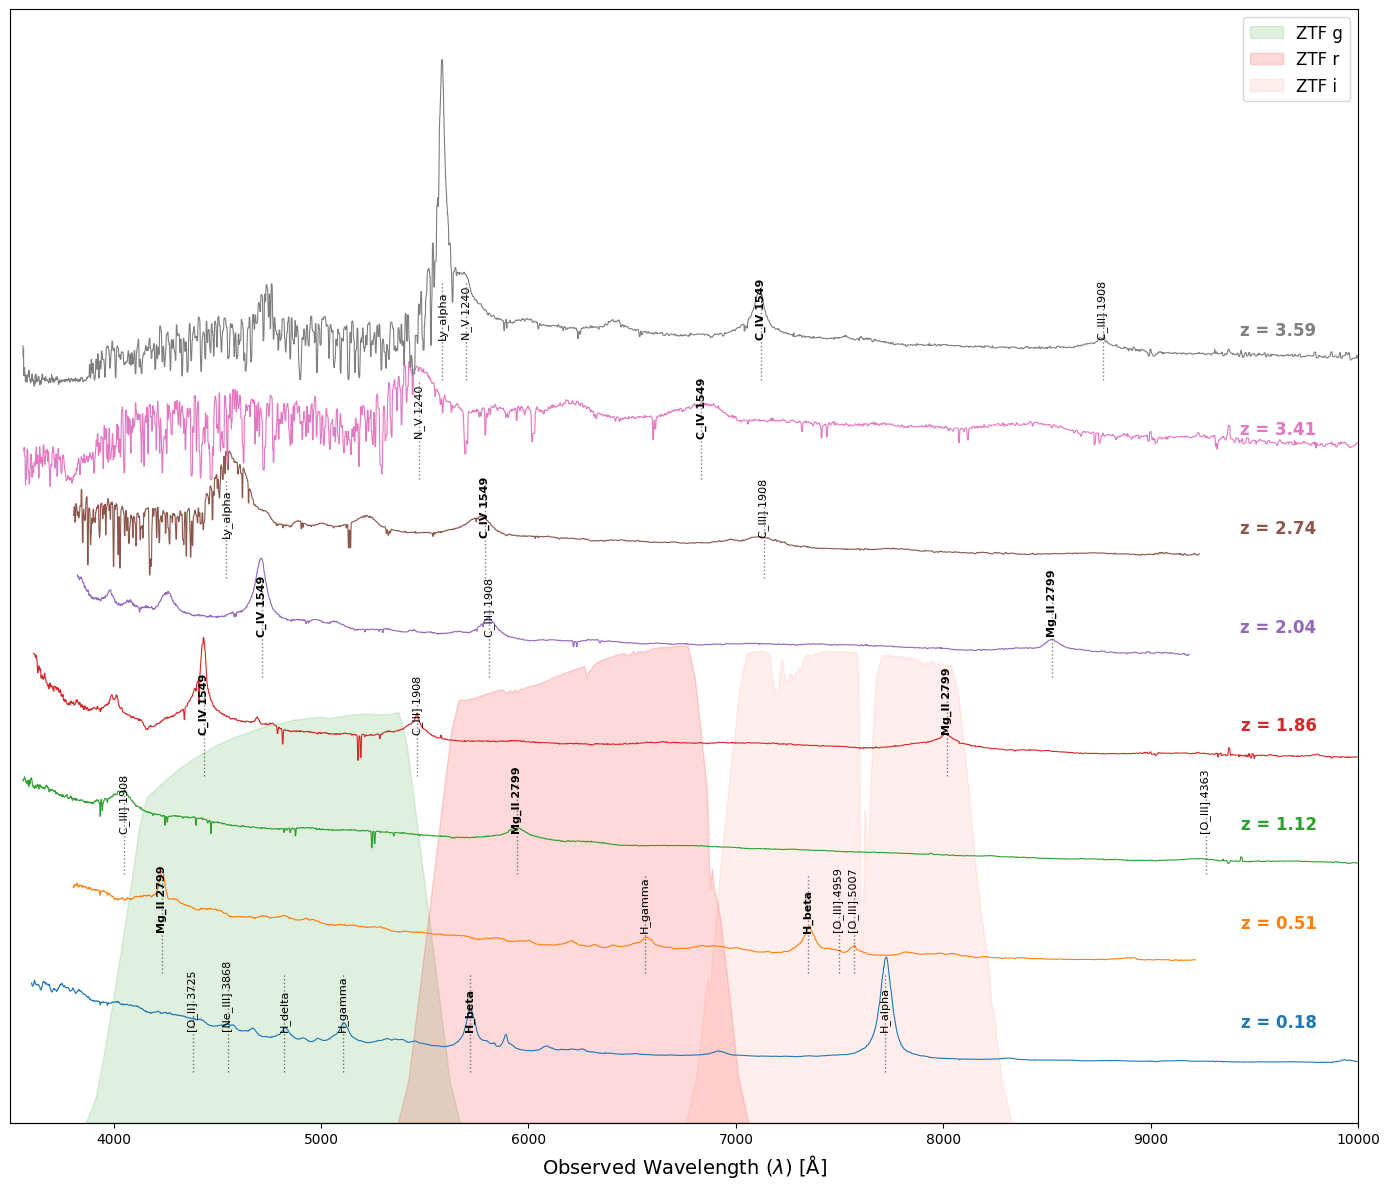

In [37]:
# 3. Create the Plot
fig, ax1 = plt.subplots(figsize=(14, 12))

# --- Plotting Parameters (Adjust these to fine-tune the visualization) ---
OFFSET_STEP = 1.2          # Vertical distance between stacked spectra
TEXT_Z_X_POS = 9800         # Fixed X position for the redshift label
TEXT_Z_Y_OFFSET = 0.5      # Upward shift for the redshift label above the spectrum
MARKER_LINE_HEIGHT = 1.2    # Height of the dotted emission line marker
MARKER_TEXT_OFFSET = 0.5    # Upward shift for the emission line name
MIN_LINE_DISTANCE = 25     # Minimum horizontal distance (in Angstroms) to avoid text overlap
# -------------------------------------------------------------------------

# Fundamental rest-frame wavelengths used by Wu & Shen for BH mass
FUNDAMENTAL_WAVES = [1549, 2798, 4861] # C IV, Mg II, H-beta

# Plot filters in the background
ax2 = ax1.twinx()
for banda, df in filtros.items():
    if df is not None:
        ax2.fill_between(df["wavelength"], df["transmission"], color=cores_ztf[banda], alpha=0.15, label=f"ZTF {banda}")
ax2.set_ylim(0, 1.1)
ax2.set_yticks([])

current_offset = 0.0
cmap = plt.get_cmap('tab10')

for i, spec in enumerate(spectra_data):
    wave = spec['wavelength']
    flux = spec['flux']
    z = spec['z']
    lines = spec['lines']
    
    flux_smoothed = median_filter(flux.astype(float), size=5)
    
    norm_factor = np.percentile(flux_smoothed[flux_smoothed > 0], 95)
    if norm_factor == 0: norm_factor = 1 
    
    flux_norm = (flux_smoothed / norm_factor) + current_offset
    
    color = cmap(i % 10)
    ax1.plot(wave, flux_norm, color=color, lw=0.8)
    
    ax1.text(TEXT_Z_X_POS, current_offset + TEXT_Z_Y_OFFSET, f"z = {z:.2f}", 
             color=color, fontsize=12, fontweight='bold', ha='right', va='bottom')
    
    # Process and filter lines for overlap and priority
    processed_lines = []
    for line in lines:
        obs_wave = line['wave_rest'] * (1 + z)
        
        # Check if line is within visible range
        if 3500 < obs_wave < 10000:
            # Check if it's one of the fundamental lines (allowing a +/- 15 Angstroms tolerance)
            is_fund = any(abs(line['wave_rest'] - fw) < 15 for fw in FUNDAMENTAL_WAVES)
            
            processed_lines.append({
                'name': line['name'],
                'obs_wave': obs_wave,
                'snr': line['snr'],
                'is_fund': is_fund
            })
            
    # Priority sorting: First by 'is_fund' (True=1, False=0), then by 'snr' (both descending)
    processed_lines.sort(key=lambda x: (x['is_fund'], x['snr']), reverse=True)
    
    # Greedy filtering to prevent overlap
    final_lines_to_plot = []
    for p_line in processed_lines:
        overlap = False
        for f_line in final_lines_to_plot:
            if abs(p_line['obs_wave'] - f_line['obs_wave']) < MIN_LINE_DISTANCE:
                overlap = True
                break
        
        # If no higher-priority line is too close, add it to the final list
        if not overlap:
            final_lines_to_plot.append(p_line)
            
    # Draw the surviving lines
    for line in final_lines_to_plot:
        # Give fundamental lines a slightly bolder treatment for emphasis
        font_weight = 'bold' if line['is_fund'] else 'normal'
        
        ax1.plot([line['obs_wave'], line['obs_wave']], 
                 [current_offset, current_offset + MARKER_LINE_HEIGHT], 
                 color='black', linestyle=':', alpha=0.5, lw=1)
        
        ax1.text(line['obs_wave'], current_offset + MARKER_TEXT_OFFSET, line['name'], 
                 fontsize=8, fontweight=font_weight, ha='center', va='bottom', rotation=90, color='black')
    
    current_offset += OFFSET_STEP

# 4. Final Formatting
ax1.set_xlabel(r'Observed Wavelength ($\lambda$) [Å]', fontsize=14, color='black')
ax1.set_ylabel('')
ax1.set_yticks([])
ax1.set_xlim(3500, 10000)

ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.spines['left'].set_visible(False)

leg = ax2.legend(loc='upper right', fontsize=12, frameon=True)
ax1.set_zorder(ax2.get_zorder() + 1)
ax1.patch.set_visible(False)

plt.tight_layout()
plt.show()

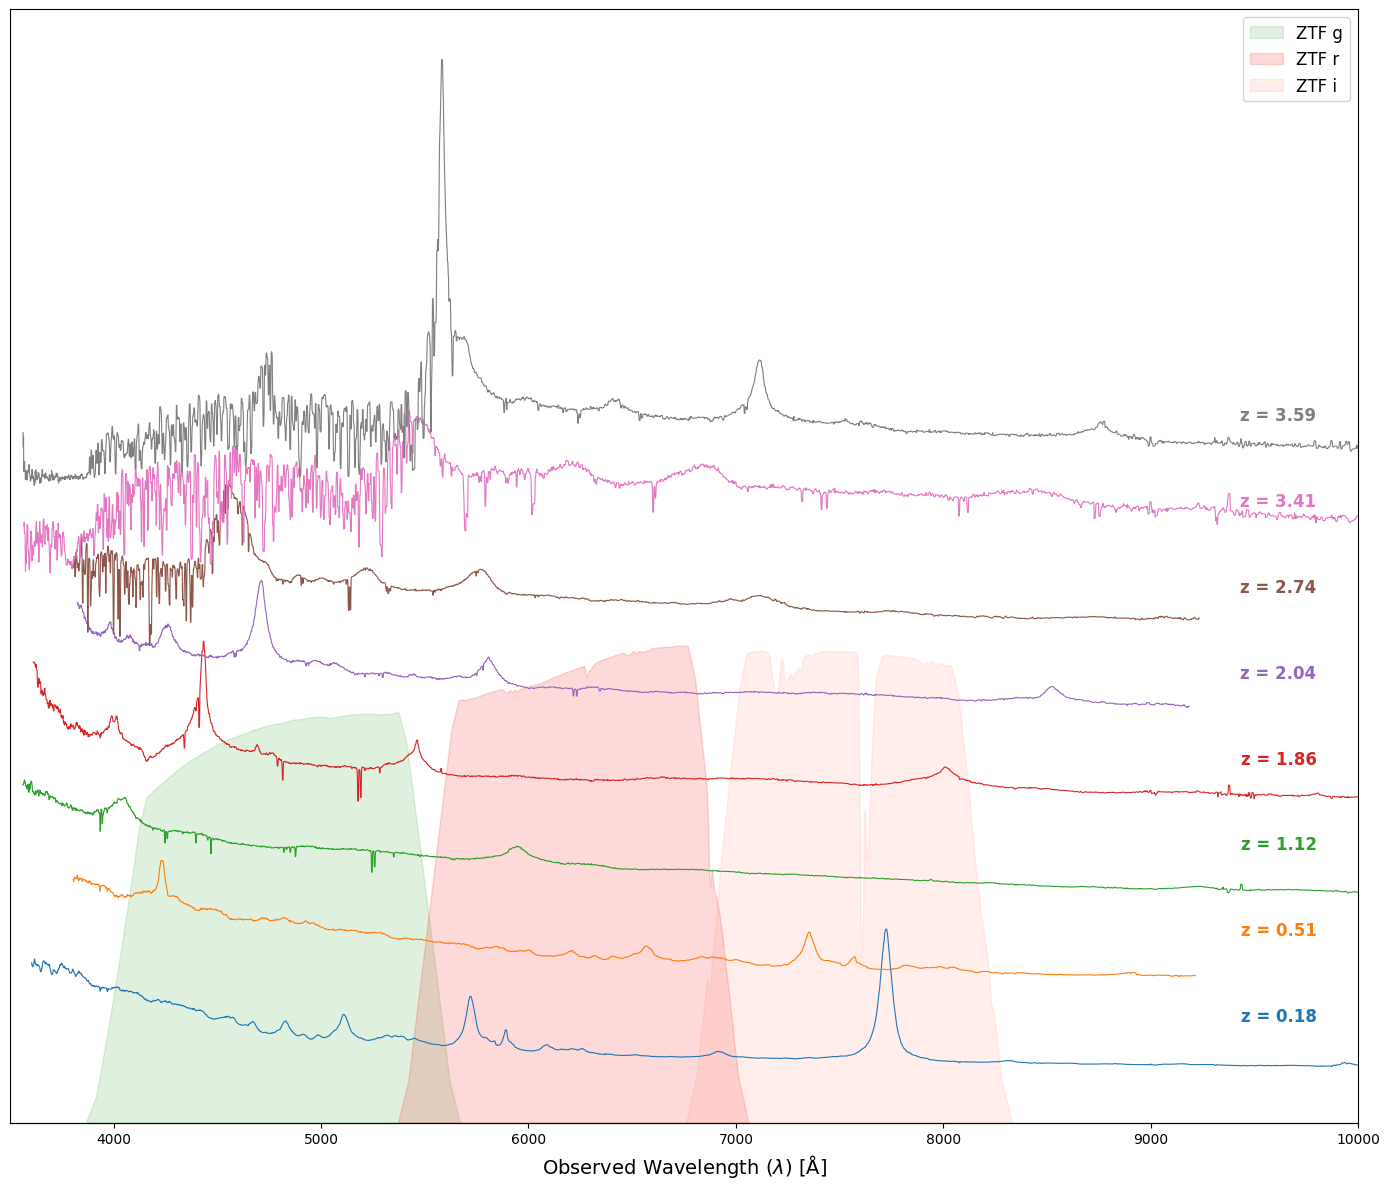

In [39]:
# ---------------------------------------------------------
# BLOCK 1: Stacked Plot WITHOUT Emission Lines
# ---------------------------------------------------------
fig_clean, ax1_clean = plt.subplots(figsize=(14, 12))

# Adjusted parameter for closer stacking
OFFSET_STEP_NO_LINES = 0.8
TEXT_Z_X_POS = 9800
TEXT_Z_Y_OFFSET = 0.5

# Plot filters in the background
ax2_clean = ax1_clean.twinx()
for banda, df in filtros.items():
    if df is not None:
        ax2_clean.fill_between(df["wavelength"], df["transmission"], color=cores_ztf[banda], alpha=0.15, label=f"ZTF {banda}")
ax2_clean.set_ylim(0, 1.1)
ax2_clean.set_yticks([])

current_offset = 0.0
cmap = plt.get_cmap('tab10')

for i, spec in enumerate(spectra_data):
    wave = spec['wavelength']
    flux = spec['flux']
    z = spec['z']
    
    flux_smoothed = median_filter(flux.astype(float), size=5)
    
    norm_factor = np.percentile(flux_smoothed[flux_smoothed > 0], 95)
    if norm_factor == 0: norm_factor = 1 
    
    flux_norm = (flux_smoothed / norm_factor) + current_offset
    
    color = cmap(i % 10)
    ax1_clean.plot(wave, flux_norm, color=color, lw=0.8)
    
    ax1_clean.text(TEXT_Z_X_POS, current_offset + TEXT_Z_Y_OFFSET, f"z = {z:.2f}", 
             color=color, fontsize=12, fontweight='bold', ha='right', va='bottom')
    
    current_offset += OFFSET_STEP_NO_LINES

# Formatting
ax1_clean.set_xlabel(r'Observed Wavelength ($\lambda$) [Å]', fontsize=14, color='black')
ax1_clean.set_ylabel('')
ax1_clean.set_yticks([])
ax1_clean.set_xlim(3500, 10000)

ax1_clean.spines['top'].set_visible(False)
ax1_clean.spines['right'].set_visible(False)
ax1_clean.spines['left'].set_visible(False)

leg = ax2_clean.legend(loc='upper right', fontsize=12, frameon=True)
ax1_clean.set_zorder(ax2_clean.get_zorder() + 1)
ax1_clean.patch.set_visible(False)

plt.tight_layout()
plt.show()

Generating GIF... This might take a minute depending on the number of spectra.
Animation saved successfully as 'quasar_evolution_ztf.gif' in your current folder.


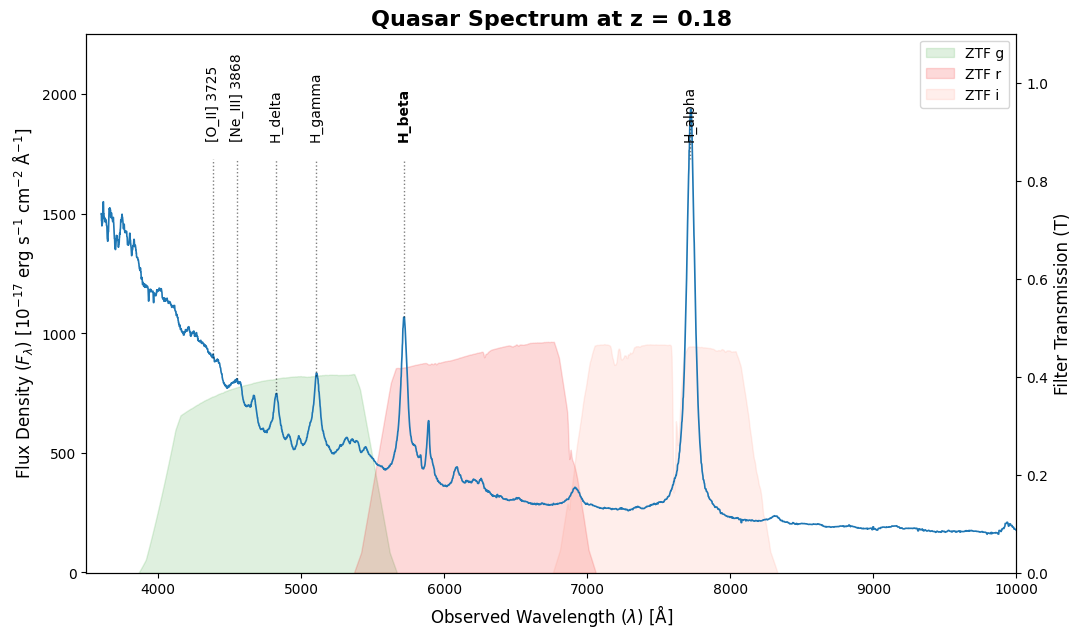

In [41]:
# ---------------------------------------------------------
# BLOCK 2: GIF Animation over Redshifts (UPDATED)
# ---------------------------------------------------------
from matplotlib.animation import FuncAnimation, PillowWriter
import numpy as np

fig_anim, ax1_anim = plt.subplots(figsize=(12, 7))
ax2_anim = ax1_anim.twinx()

FUNDAMENTAL_WAVES = [1549, 2798, 4861]
MIN_LINE_DISTANCE = 150

def update(frame_index):
    # Clear axes for the next frame
    ax1_anim.clear()
    ax2_anim.clear()
    
    spec = spectra_data[frame_index]
    wave = spec['wavelength']
    flux = spec['flux']
    z = spec['z']
    lines = spec['lines']
    
    flux_smoothed = median_filter(flux.astype(float), size=5)
    
    # Plot ZTF filters on ax2 (transmission)
    for banda, df in filtros.items():
        if df is not None:
            # Added label argument here so the legend can pick it up
            ax2_anim.fill_between(df["wavelength"], df["transmission"], color=cores_ztf[banda], alpha=0.15, label=f"ZTF {banda}")
            
    ax2_anim.set_ylim(0, 1.1)
    
    # Force the Y-label and ticks to strictly remain on the right side after clearing
    ax2_anim.yaxis.set_label_position("right")
    ax2_anim.yaxis.tick_right()
    ax2_anim.set_ylabel('Filter Transmission (T)', fontsize=12)
    
    # Add the legend for filters
    ax2_anim.legend(loc='upper right', fontsize=10, frameon=True)
    
    # Plot the spectrum on ax1 (absolute flux)
    color = plt.get_cmap('tab10')(frame_index % 10)
    ax1_anim.plot(wave, flux_smoothed, color=color, lw=1.2)
    
    # Set dynamic Y-limits based on the current spectrum's 99th percentile
    max_flux = np.percentile(flux_smoothed[flux_smoothed > 0], 99)
    if max_flux <= 0: max_flux = 1
    ax1_anim.set_ylim(bottom=-1.0, top=max_flux * 1.5)
    
    # ---------------------------------------------------------
    # Emission lines processing and plotting
    # ---------------------------------------------------------
    processed_lines = []
    for line in lines:
        obs_wave = line['wave_rest'] * (1 + z)
        if 3500 < obs_wave < 10000:
            is_fund = any(abs(line['wave_rest'] - fw) < 15 for fw in FUNDAMENTAL_WAVES)
            processed_lines.append({
                'name': line['name'],
                'obs_wave': obs_wave,
                'snr': line['snr'],
                'is_fund': is_fund
            })
            
    processed_lines.sort(key=lambda x: (x['is_fund'], x['snr']), reverse=True)
    
    final_lines_to_plot = []
    for p_line in processed_lines:
        overlap = False
        for f_line in final_lines_to_plot:
            if abs(p_line['obs_wave'] - f_line['obs_wave']) < MIN_LINE_DISTANCE:
                overlap = True
                break
        if not overlap:
            final_lines_to_plot.append(p_line)
            
    # Draw the surviving lines dynamically scaled to the current frame's height
    for line in final_lines_to_plot:
        font_weight = 'bold' if line['is_fund'] else 'normal'
        
        # Find the approximate Y value on the spectrum to anchor the dotted line
        idx = (np.abs(wave - line['obs_wave'])).argmin()
        y_base = flux_smoothed[idx]
        y_top = max_flux * 1.15
        
        ax1_anim.plot([line['obs_wave'], line['obs_wave']], 
                      [y_base, y_top], 
                      color='black', linestyle=':', alpha=0.5, lw=1)
        
        ax1_anim.text(line['obs_wave'], y_top + (max_flux * 0.05), line['name'], 
                      fontsize=10, fontweight=font_weight, ha='center', va='bottom', rotation=90, color='black')
    # ---------------------------------------------------------
    
    ax1_anim.set_xlim(3500, 10000)
    ax1_anim.set_xlabel(r'Observed Wavelength ($\lambda$) [Å]', fontsize=12)
    ax1_anim.set_ylabel(r'Flux Density ($F_\lambda$) [$10^{-17}$ erg s$^{-1}$ cm$^{-2}$ Å$^{-1}$]', fontsize=12)
    
    ax1_anim.set_title(f"Quasar Spectrum at z = {z:.2f}", fontsize=16, fontweight='bold')
    
    ax1_anim.set_zorder(ax2_anim.get_zorder() + 1)
    ax1_anim.patch.set_visible(False)
    
    return ax1_anim, ax2_anim

print("Generating GIF... This might take a minute depending on the number of spectra.")

# fps=0.25 saves the GIF at 4 seconds per frame
anim = FuncAnimation(fig_anim, update, frames=len(spectra_data), interval=4000, blit=False)
gif_filename = "quasar_evolution_ztf.gif"
anim.save(gif_filename, writer=PillowWriter(fps=0.25))

print(f"Animation saved successfully as '{gif_filename}' in your current folder.")